# aoctrl quickstart — same code as the CLI, interactively

Everything here calls the library used by `python -m aoctrl.cli ...`. Configs come from `configs/` via Hydra's
compose API, so any CLI override string works here too.

* `system=synthetic` runs in seconds without OOPAO; use `system=scao` (the original notebook's system) or `system=mcao`.
* Expensive artifacts (calibration, turbulence series, reference runs, identification data) are cached in `cache/`;
  trained models are checkpointed in `checkpoints/` and reloaded automatically.

In [3]:
%matplotlib inline
from aoctrl.api import load_config, build_context, run_experiment
from aoctrl.simulation import simulate
from aoctrl.viz import plots

SYSTEM = "scao" #"synthetic"          # "scao" for OOPAO (as in OOPAO_init.ipynb), "mcao" for multi-conjugate
COMMON = [f"system={SYSTEM}", "eval=quick", "close_figures=false"]

## 1. Explore components interactively (no experiment needed)

In [4]:
cfg = load_config(COMMON)
ctx = build_context(cfg)
print(ctx.backend.description)
calib = ctx.calibration                      # cached after the first call
print("M2C", calib.M2C.shape, "| D", calib.D.shape, "| cond %.1f" % calib.cond)
print("modal basis explains %.1f %% of the OPD variance" % (100 * ctx.turbulence.explained_variance))
print({p: m.coefs.shape for p, m in ctx.ar_models.items()}, "| DM sign", ctx.dm_sign["sign"])



     °          *      *      
 ▄██▄   ▄██▄  ▄███▄   ▄██▄ * ▄██▄ 
██* ██ ██  ██ ██  ██ ██  ██ ██  ██
██  ██ ██° ██ ██  ██ ██* ██ ██  ██
██  ██ ██  ██ ████▀  ██▄▄██ ██  ██
██* ██ ██  ██ ██     ██▀▀██ ██  ██
██  ██ ██  ██ ██ *   ██  ██ ██* ██
 ▀██▀   ▀██▀  ██   ° ██  ██  ▀██▀ 
      *         *             



------------ Telescope -------------
Diameter [m]             |   8.00   
Resolution [px]          |   120    
Pixel size [m]           |   0.07   
Surface [m²]             |  50.24   
Central obstruction [%]  |    0     
Pixels in pupil          |  11304   
Field of view [arcsec]   |   0.00   
------------------------------------


------------- Source --------------
Source                   |   NGS   
Wavelength [m]           | 7.9e-07 
Zenith [arcsec]          |  0.00   
Azimuth [°]              |  0.00   
Altitude [m]             |   inf   
Magnitude                |  8.00   
Flux [photon/m²/s]       | 4.6e+06 
Coordinates [arcsec,deg] | [0,0]
--------------------------------

Updating the Atmosphere covariance matrices...
Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06


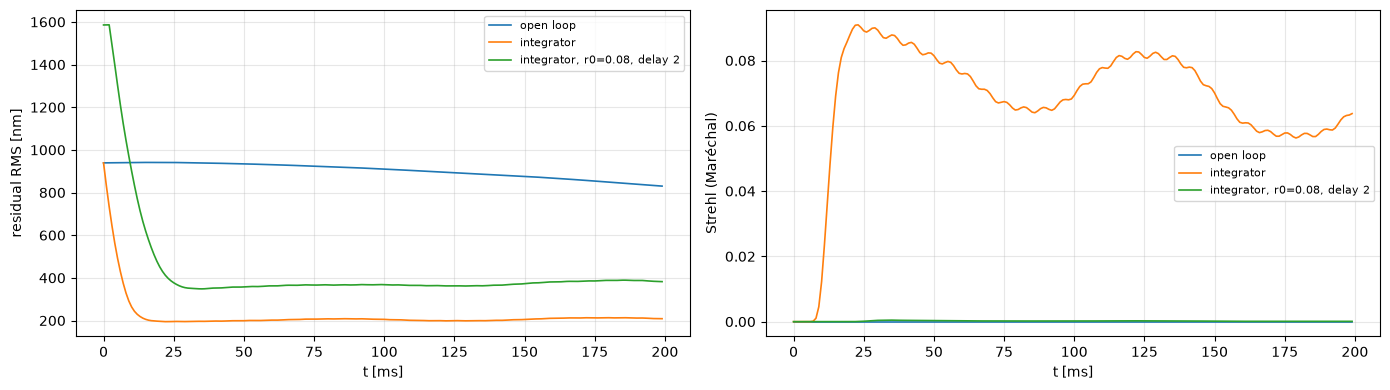

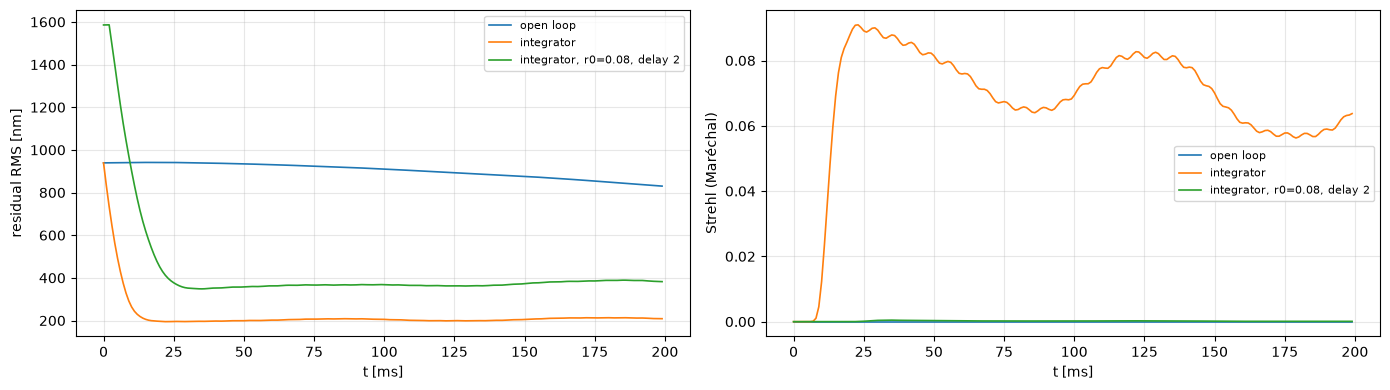

In [5]:
# the plant: step(u) -> y, with delay / saturation / operating conditions
ol = simulate(ctx.plant, 200, None, seed=1, projector=calib.Bpinv)
cl = simulate(ctx.plant, 200, ctx.integrator(), seed=1, projector=calib.Bpinv)
with ctx.plant.conditions(r0=0.08, delay=2):
    cl_hard = simulate(ctx.plant, 200, ctx.integrator(), seed=1)
plots.plot_timeseries({"open loop": ol, "integrator": cl, "integrator, r0=0.08, delay 2": cl_hard}, ctx.ts_ms)

## 2. Run a full experiment (identical to `python -m aoctrl.cli experiment=exp1_oracle_lqr ...`)

[12:53:37][aoctrl.api][WARNING] the given context was built from a different config; building a new one
[12:53:37][aoctrl.api][INFO] experiment exp1_oracle_lqr | system scao | output /Users/waltermayor/workspace/mila/clases/bacon_rl/repo_project/outputs/exp1_oracle_lqr/2026-11-24_12-53-37
[12:53:37][aoctrl.utils.cache][INFO] cache hit: calibration/24b71046b4b9
[12:53:37][aoctrl.utils.cache][INFO] cache hit: turbulence/7fc3b68b9b33
[12:53:37][aoctrl.utils.cache][INFO] cache hit: dm_sign/b6258cc2be93
[12:53:37][aoctrl.experiments.base][INFO] modal basis explains 95.7 % of OPD variance; DM sign +1 (slope 1.000, rel. err 2.9e-15)



------------ Telescope -------------
Diameter [m]             |   8.00   
Resolution [px]          |   120    
Pixel size [m]           |   0.07   
Surface [m²]             |  50.24   
Central obstruction [%]  |    0     
Pixels in pupil          |  11304   
Field of view [arcsec]   |   0.00   
------------------------------------


------------- Source --------------
Source                   |   NGS   
Wavelength [m]           | 7.9e-07 
Zenith [arcsec]          |  0.00   
Azimuth [°]              |  0.00   
Altitude [m]             |   inf   
Magnitude                |  8.00   
Flux [photon/m²/s]       | 4.6e+06 
Coordinates [arcsec,deg] | [0,0]
-----------------------------------

Creation of layer1/1 ...
-> Computing the initial phase screen...
initial phase screen : 0.02390599250793457 s
ZZt.. : 0.25951385498046875 s
ZXt.. : 0.0823049545288086 s
XXt.. : 0.050176143646240234 s
Done!
Updating the Atmosphere covariance matrices...

------------------------- Atmosphere @ Elevation = 

[12:53:41][aoctrl.experiments.context][INFO] backend: SCAO: 1 GS / 1 pyramid / 1 DM / 1 layer(s)



----------- Pyramid WFS ------------
Pupil diameter [px]      |   10    
Pupil separation [px]    |  2.00   
Field of view [arcsec]   |  2.44   
Modulation radius [l/D]  |   3.0   
PSF sampling [px/(l/D)]  |  2.40   
PSF centering            |  True   
Valid pixels             |   160   
Post processing          |slopesMaps
------------------------------------

Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06


[12:54:24][aoctrl.evaluation.sweep][INFO] [normal, delay=0] done (44 s)


Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06
Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06


[12:55:05][aoctrl.evaluation.sweep][INFO] [strong, delay=0] done (84 s)
[12:55:05][aoctrl.utils.cache][INFO] computed references in 86.6 s
[12:55:05][aoctrl.experiments.base][INFO] 
=== regime normal | DM delay 0 frame(s) | fitting floor 189 nm ===
         controller  rms  rms_std  strehl        u  retained  est_err  nis   t_ms
          open loop  568        0 1.4e-09        0       NaN      NaN  NaN    NaN
          I (g=0.4)  216        0  0.0522 3.27e+03         0      NaN  NaN 0.0336
   LQR oracle AR(1)  188        0   0.107 3.38e+03      99.7      NaN  NaN 0.0464
   LQR oracle AR(2)  188        0   0.107 3.42e+03       100      NaN  NaN 0.0727
LQR oracle persist.  188        0   0.107 3.38e+03      99.7      NaN  NaN 0.0682

=== regime strong | DM delay 0 frame(s) | fitting floor 319 nm ===
         controller  rms  rms_std   strehl        u  retained  est_err  nis   t_ms
          open loop  960        0 7.23e-26        0       NaN      NaN  NaN    NaN
          I (g=0.4)  389 

Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06
Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06
Updating the Atmosphere covariance matrices...
Flux updated, magnitude is  8 and flux is 4.61e+06


[12:57:31][aoctrl.api][INFO] summary saved to /Users/waltermayor/workspace/mila/clases/bacon_rl/repo_project/results/exp1_oracle_lqr/bffd3b22ef35/summary.csv


,regime,delay,controller,tag,rms,rms_std,strehl,u,retained,est_err,nis,t_ms,fitting_floor,n_seeds
0,normal,0,open loop,-,568.351480,0.0,1.400295e-09,0.000000,NaN,NaN,NaN,NaN,188.746929,1
1,normal,0,I (g=0.4),ref,216.066156,0.0,5.219920e-02,3267.301092,0.000000,NaN,NaN,0.033555,188.746929,1
2,normal,0,LQR oracle AR(1),,187.970978,0.0,1.070115e-01,3379.969174,99.748209,NaN,NaN,0.046415,188.746929,1
3,normal,0,LQR oracle AR(2),Exp 1,187.900059,0.0,1.071918e-01,3415.660190,100.000000,NaN,NaN,0.072703,188.746929,1
4,normal,0,LQR oracle persist.,,187.971483,0.0,1.070102e-01,3382.608980,99.746417,NaN,NaN,0.068230,188.746929,1
5,strong,0,open loop,-,959.661464,0.0,7.226544e-26,0.000000,NaN,NaN,NaN,NaN,318.699186,1
6,strong,0,I (g=0.4),ref,388.542195,0.0,7.150171e-05,5120.387977,0.000000,NaN,NaN,0.243682,318.699186,1
7,strong,0,LQR oracle AR(1),,317.388993,0.0,1.712180e-03,5707.077886,99.831987,NaN,NaN,0.050210,318.699186,1
8,strong,0,LQR oracle AR(2),Exp 1,317.269245,0.0,1.720393e-03,5767.342166,100.000000,NaN,NaN,0.052100,318.699186,1
9,strong,0,LQR oracle persist.,,317.389845,0.0,1.712121e-03,5711.535199,99.830791,NaN,NaN,0.051718,318.699186,1


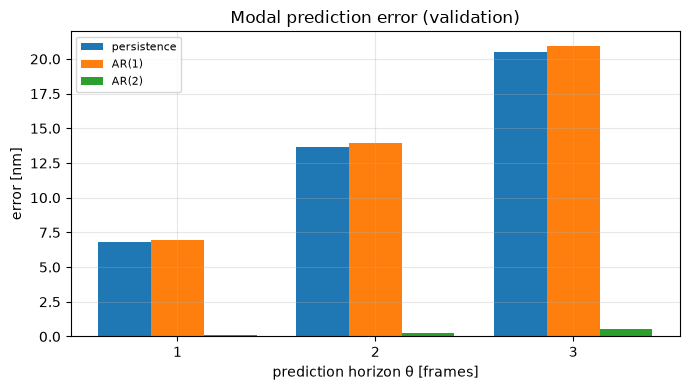

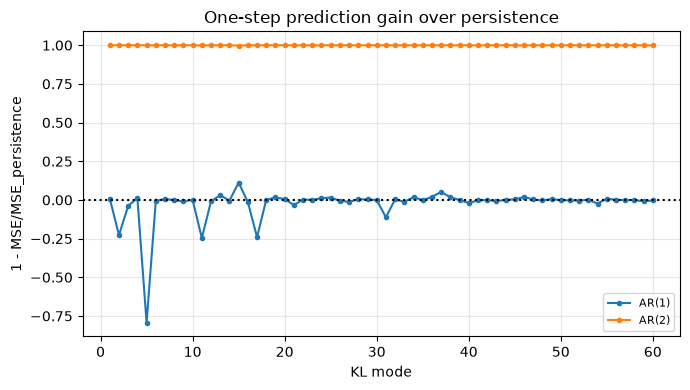

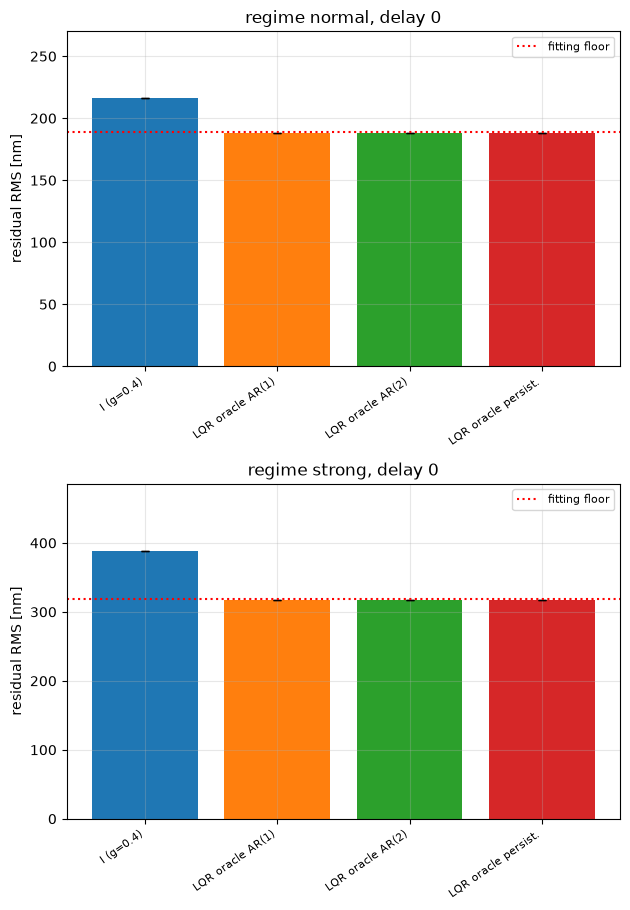

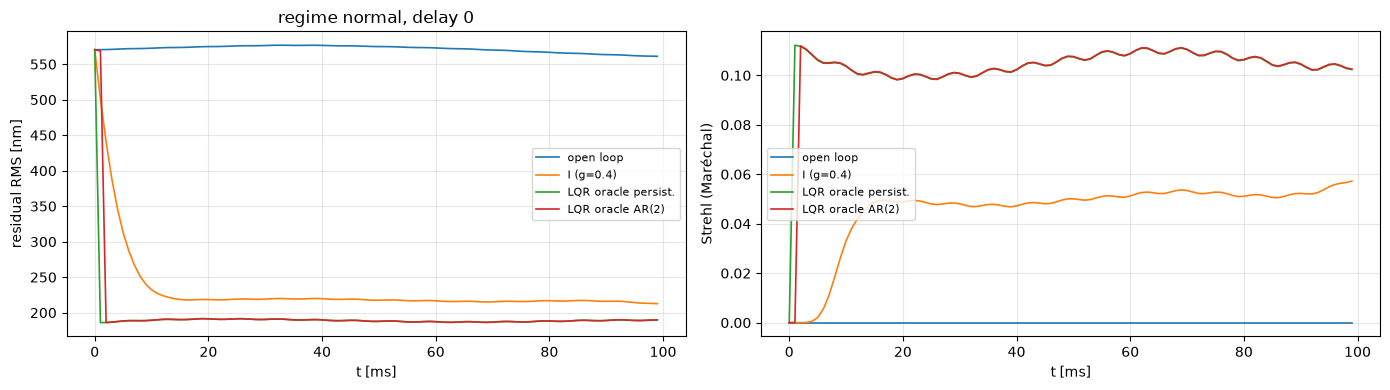

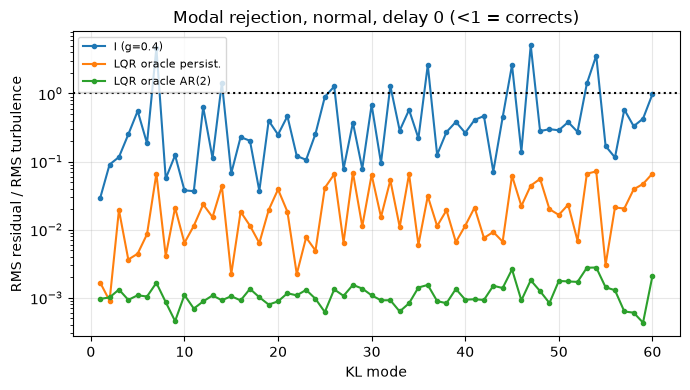

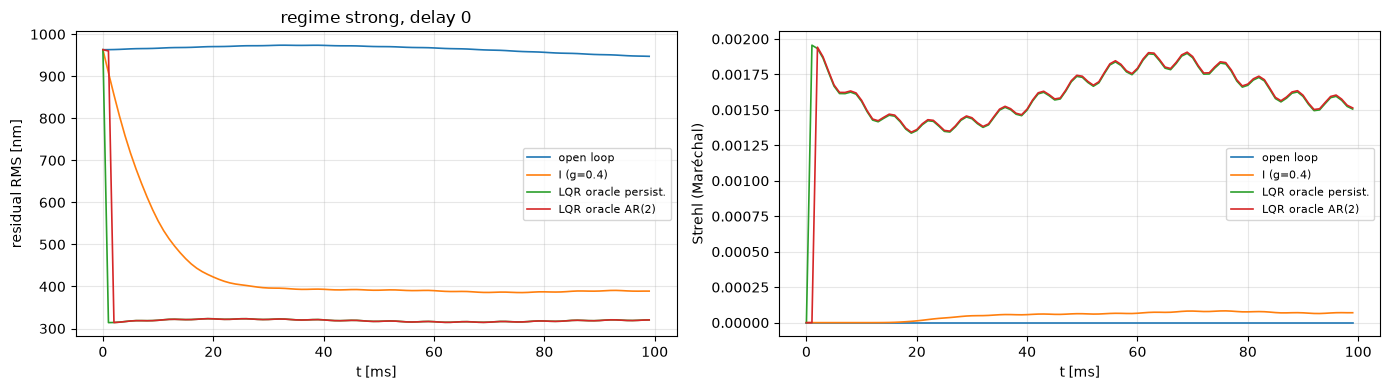

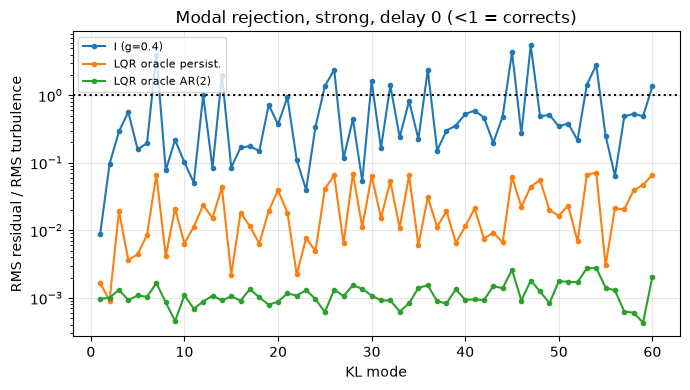

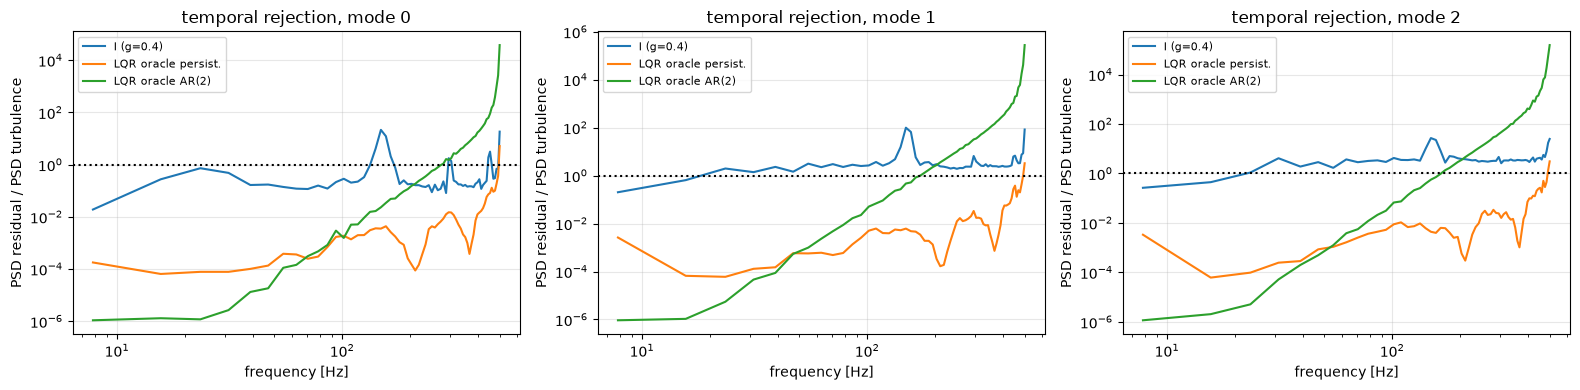

In [6]:
res1 = run_experiment(load_config(COMMON + ["experiment=exp1_oracle_lqr"]), ctx=ctx)
res1.summary

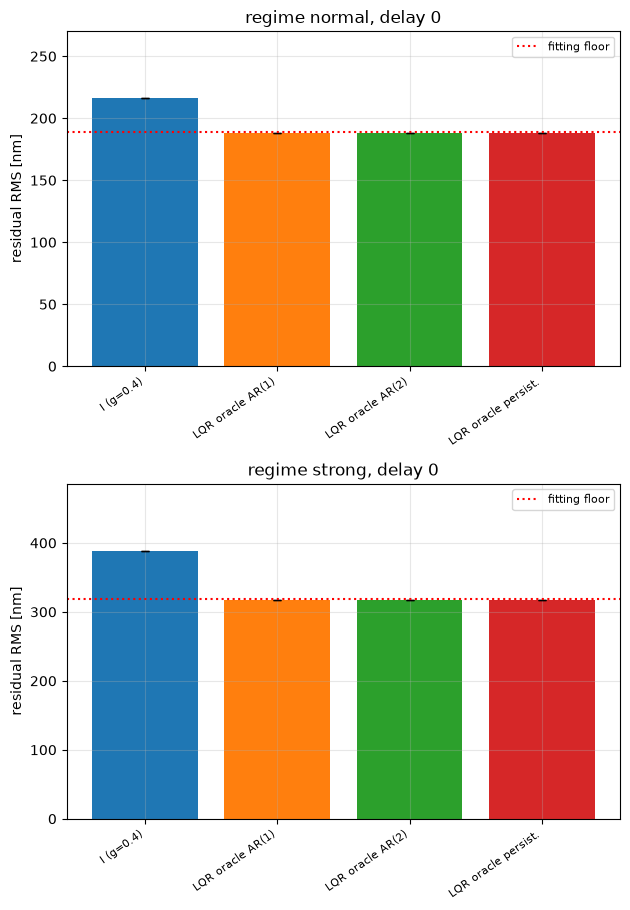

In [7]:
res1.figures["rms_bars"]

## 3. Learned latent (Experiment 3): trains on GPU if available, reuses the checkpoint on the next run

In [ ]:
res3 = run_experiment(load_config(COMMON + ["experiment=exp3_latent_lqr", "model.train.steps=500"]), ctx=ctx)
print("loaded from checkpoint:", res3.metrics["exp3_structured_latent/from_checkpoint"])
res3.summary

In [ ]:
res3.figures["training"]

## 4. Videos and component studies

In [ ]:
res_p = run_experiment(load_config(COMMON + ["experiment=study_plant", "video.enabled=true", "video.n_steps=100"]), ctx=ctx)
from IPython.display import Video
Video(res_p.artifacts["videos"]["closed_loop"], embed=True)